# Week 8 activity · The Tube, three ways

**LDSCI6253 Information Presentation & Data Visualisation** · Northeastern University London

In the tutorial notebook you built networks and trees step by step. Now use the same moves on new questions
about the London Underground in Zone 1. Keep the tutorial open beside this: each part says which section to
look back at.

| Part | You will… | Tutorial | Time |
|---|---|---|---|
| Warm-up | remember three ideas | – | 2 min |
| **A** | find out what one row of the data really is | §1 | 10 min |
| **B** | count **degree** two ways | §1, §4 | 10 min |
| **C** | draw the Tube as **dots and lines**, sized by how many lines stop there | §3, §4, §6a | 15 min |
| **D** | turn the Tube into a network of **lines**, drawn as a **grid** | §5, §5b | 25 min |
| **F** | choose the right picture for three readers | §0, §6 | 10 min |
| **E** | test whether the Tube is a **tree** (if you have time, or at home) | §6c, §6 | 10 min |

**How to work, in pairs.** One of you types, the other is the checker. Before each Run, the checker says what
they expect to see; after it, compare. Swap at each new letter.

- Where you see `___`, replace it with code, then run the cell (Shift + Enter). Run cells **in order**.
- After many cells a ✅ or ❌ line tells you if you are on track.
- Stuck? Open the 💡 **Hint**, then look at the tutorial section named.
- Write your answers in the ✏️ cells (double-click to type, Shift + Enter to finish).

**If you get an error**
- `NameError: name '…' is not defined`: a cell above was not run. Run the cells above, in order.
- `SyntaxError` pointing at `___`: a blank is still empty.
- `KeyError: '…'`: a column name is misspelt. Check it against the table's `.head()`.
- A chart that is empty, or has no labels: a name inside quotes is misspelt (`'lines:Q'`, `'datum.lines'`).

# Teacher copy: solutions, timings and marking

This is the student activity with every blank filled in and run. Under each code cell, 👀 says in plain words
what students should see, and the chart cells have a picture of the expected chart (plan B: if Python will not
run, put the pictures on screen and run C–F as a discussion). The student copy is
`08_Activity_IPDV_Tube_Networks.ipynb`; both come from `tools/ipdv-week8/code/activity.py`, so they always match.

| Part | What students do | Time | The point |
|---|---|---|---|
| Setup + warm-up | Open, run the first cell; recall degree, tree, the three questions | 5 min | Retrieval before new work |
| A | Read the two tables; drop repeated track | 10 min | A row is one *line's* track between two stations, so 130 rows are only 90 pairs |
| B | Degree two ways | 10 min | "Busiest" depends on what you count: King's Cross by edges, Oxford Circus, Green Park and Waterloo by neighbours |
| C | Node-link map sized by lines | 15 min | Position is geography here; size is data (number of lines) |
| D | Lines that share stations, as a grid | 25 min | 11 lines, 48 linked pairs, each with a weight: a grid beats dots and lines |
| F | Choose and justify | 10 min | The reader's question picks the picture |
| E | Is it a tree? (if time, or homework) | 10 min | 43 of 65 stations have more than one parent line; forcing a tree counts 139 stations for 65 |

**Learning outcomes:** read an edge list; compute degree and say what it counts; build node-link and matrix
views in Altair; recognise when data is (and is not) a tree; justify a choice of picture by the reader's task.

**Setup:** students need Python with `altair` and `pandas` (VS Code with the Jupyter extension, JupyterLab, or
Google Colab). The two CSVs should sit beside the notebook; if not, `load()` fetches them from the course site
(it can take 30 seconds to wake up the first time).

**When a student is stuck: what they will see and what to say**

| They see | It means | Say |
|---|---|---|
| `NameError: name 'served' is not defined` | A cell above was skipped | "Run the cells above, in order (or Run All Above)." |
| `SyntaxError` at `___` | A blank is still empty | "Which blank is left? Open the hint." |
| `KeyError: 'line_x'` (in D1) | The merge in D1a used the wrong column | "What do two lines have in common? Merge on that column." |
| `KeyError` with a column name | A misspelt column | "Compare with `.head()` of the table." |
| A chart with no labels, or empty | A misspelt name inside quotes | "Check the spelling of the name inside the quotes." |
| `SchemaValidationError … invalid value for field` | A table or variable was given where a column name in quotes is needed | "Altair wants the column's name in quotes, like `'lines:Q'`." |
| ❌ on a check line | The cell ran, but the answer is off | "Read the ❌ message; it says what to look at." |
| Charts do not show at all | The notebook's chart renderer is not working | "Restart the kernel and Run All; or use the plan B pictures." |

## 0 · Set up

Run this cell first. It loads the two tables and gives the Tube lines their proper names.

In [1]:
import altair as alt
import pandas as pd
from pathlib import Path

LIVE = "https://slideforge-rpjj.onrender.com/assets/lesson/ipdv/week8/"

def load(name):
    """Read name.csv from beside this notebook, or from the course site if it is not here."""
    here = Path(name + ".csv")
    return pd.read_csv(here if here.exists() else LIVE + name + ".csv")

def check(ok, good, hint):
    """Print ✅ and what you found, or ❌ and what to look at."""
    print('✅ ' + good if ok else '❌ Not yet: ' + hint)

stations = load('tube_stations')   # name, lon, lat, zone: one row per station
edges = load('tube_links')         # source, target, line, colour: one row per ...? (Part A finds out)

# Readers should see 'Hammersmith & City', not the data's code 'hammersmith-city'
NAMES = {'bakerloo': 'Bakerloo', 'central': 'Central', 'circle': 'Circle', 'district': 'District',
         'hammersmith-city': 'Hammersmith & City', 'jubilee': 'Jubilee', 'metropolitan': 'Metropolitan',
         'northern': 'Northern', 'piccadilly': 'Piccadilly', 'victoria': 'Victoria', 'waterloo-city': 'Waterloo & City'}
edges['line'] = edges['line'].map(NAMES)
edges.head()

,source,target,line,colour
0,Elephant & Castle,Lambeth North,Bakerloo,#B36305
1,Lambeth North,Waterloo,Bakerloo,#B36305
2,Embankment,Waterloo,Bakerloo,#B36305
3,Charing Cross,Embankment,Bakerloo,#B36305
4,Charing Cross,Piccadilly Circus,Bakerloo,#B36305


> 👀 **You should see:** a table of five rows: two station names, a line name (e.g. Bakerloo) and a colour code such as #B36305.

### Warm-up (2 min, from memory, no looking)

1. What is the **degree** of a node?
2. What makes a network a **tree**?
3. Which picture answers *"is this pair linked?"* best: dots and lines, a grid, or boxes inside boxes?

> **Teacher:** **Expected:** (1) how many edges touch it; (2) every child has exactly one parent, no loops; (3) a grid. Take
> answers from two or three pairs; don't correct yet: Part B will complicate (1).

## A · What is a row? (10 min · tutorial §1)

**A1.** How many stations are there, and how many rows are in the table of edges?

In [2]:
print(len(stations), 'stations')
print(len(edges), 'rows in edges')

65 stations
130 rows in edges


> 👀 **You should see:** `65 stations` and `130 rows in edges`.

**A2.** If every row were a different piece of track, each **pair of stations** would appear once. Keep only
the first row for each pair (the same `source` and the same `target`) and count again. Tutorial §1 shows how,
with `drop_duplicates`.

In [3]:
pairs = edges.drop_duplicates(subset=['source', 'target'])
print(len(pairs), 'different pairs of stations')
check(len(pairs) == 90, 'right: 90 different pairs', 'name BOTH columns, each in quotes, as in tutorial §1')

90 different pairs of stations
✅ right: 90 different pairs


<details><summary>💡 <b>Hint</b></summary>

`subset=` takes a **list of column names, each in quotes**, like `subset=['col1', 'col2']`. Using only
`'source'` gives 45 with no error, but that keeps one row per *starting* station, not per pair.
</details>

> 👀 **You should see:** `90 different pairs of stations` and a ✅. Common slip: `subset=['source']` gives 45 (the ❌ line catches it).

**A3.** 130 rows, but only 90 pairs. Show the rows whose pair appears more than once, sorted so the repeats sit
together. Look at the `line` column.

In [4]:
edges[edges.duplicated(subset=['source', 'target'], keep=False)].sort_values(['source', 'target']).head(6)

,source,target,line,colour
40,Aldgate,Liverpool Street,Circle,#FFD300
84,Aldgate,Liverpool Street,Metropolitan,#9B0056
48,Baker Street,Edgware Road,Circle,#FFD300
76,Baker Street,Edgware Road,Hammersmith & City,#F3A9BB
47,Baker Street,Great Portland Street,Circle,#FFD300
75,Baker Street,Great Portland Street,Hammersmith & City,#F3A9BB


> 👀 **You should see:** six rows in twos and threes: Aldgate–Liverpool Street on Circle and Metropolitan; Baker Street–Edgware Road on Circle and Hammersmith & City; Baker Street–Great Portland Street on three lines.

> **Teacher:** **Expected:** 65 stations; 130 rows; 90 distinct pairs. A row is **one line's** track between two neighbouring
> stations, so where Circle, District, Hammersmith & City and Metropolitan share track, the same pair appears once
> per line.
> **Sample answers.** *Full marks:* "One row is one line's stretch of track between two neighbouring stations, so a
> pair served by three lines has three rows." *Low:* "One row is a connection." (true, but misses *which* connection.)
> **Ask the room:** "Connections between what?"

## B · Degree, two ways (10 min · tutorial §1, §4)

In the tutorial's §4 Try it, King's Cross St. Pancras came out with degree 10. But only six lines stop there,
and only five stations are one stop away. So what was counted? Count two different things:

- **edges**: every row of `edges` that touches the station (so shared track counts once per line);
- **neighbours**: how many *different* stations are one stop away (count in `pairs`, from A2).

**B1.** Count both, the same way as tutorial §1, and put them side by side.

In [5]:
by_edges = pd.concat([edges['source'], edges['target']]).value_counts()
by_neighbours = pd.concat([pairs['source'], pairs['target']]).value_counts()

degree = pd.DataFrame({'edges': by_edges, 'neighbours': by_neighbours})
check(degree.loc["King's Cross St. Pancras", 'neighbours'] == 5, "right: King's Cross has 5 neighbours",
      "count in pairs (from A2), not in edges")
degree.sort_values('neighbours', ascending=False).head(8)

✅ right: King's Cross has 5 neighbours


,edges,neighbours
Waterloo,7,6
Oxford Circus,6,6
Green Park,6,6
Baker Street,8,5
Bank,5,5
King's Cross St. Pancras,10,5
Westminster,6,4
Embankment,8,4


> 👀 **You should see:** ✅, then a table of 8 stations: Oxford Circus, Green Park and Waterloo with 6 neighbours at the top; King's Cross with 10 edges but 5 neighbours.

**B2.** How many *extra* edges does each station get from shared track? Subtract one column from the other.

In [6]:
degree['extra'] = degree['edges'] - degree['neighbours']
degree.sort_values('extra', ascending=False).head(5)

,edges,neighbours,extra
King's Cross St. Pancras,10,5,5
Edgware Road,7,3,4
Euston Square,6,2,4
Paddington,6,2,4
Barbican,6,2,4


> 👀 **You should see:** King's Cross St. Pancras on top with 5 extra, then stations on the shared Circle / Hammersmith & City / Metropolitan track (Baker Street, Moorgate…).

> **Teacher:** **Expected:** by edges, **King's Cross St. Pancras** (10) leads, then Embankment, Baker Street and Moorgate (8).
> By neighbours, **Oxford Circus, Green Park and Waterloo** (6) lead; King's Cross has 5. King's Cross is served by
> several lines running on the same track to the same neighbours, so edges count it many times over.
> **The point:** a network measure answers the question you counted for. Edges ≈ "how many trains pass";
> neighbours ≈ "how many places one stop away".
> **Sample answers.** *Full marks:* "King's Cross by edges, Oxford Circus/Green Park/Waterloo by neighbours: edges
> counts a shared piece of track once for every line on it, neighbours counts each place once." *Low:* "King's
> Cross, because it's the biggest station."

## C · Dots and lines: where the lines meet (15 min · tutorial §3, §4, §6a)

**C1.** Make a table of which lines serve each station (one row per station and line), then count the lines at
each station. This is like stacking `source` and `target` for degree, but keeping the line beside each name.

In [7]:
served = pd.concat([
    edges[['source', 'line', 'colour']].rename(columns={'source': 'station'}),
    edges[['target', 'line', 'colour']].rename(columns={'target': 'station'}),
]).drop_duplicates()

# Count the rows (lines) for each station. It is named 'lines': the chart in C2 uses that name.
lines_at = served.groupby('station')['line'].count().rename('lines')
check(lines_at.max() == 6, "right: the busiest station has 6 lines", "count the lines in each station's group")
lines_at.sort_values(ascending=False).head(6)

✅ right: the busiest station has 6 lines


station
King's Cross St. Pancras    6
Baker Street                5
Edgware Road                4
Paddington                  4
Waterloo                    4
Liverpool Street            4
Name: lines, dtype: int64

> 👀 **You should see:** ✅, then King's Cross St. Pancras 6, Baker Street 5, then stations with 4 (Embankment, Edgware Road, Liverpool Street…).

**C2.** Draw the Tube as in tutorial §4, but **size each station by how many lines stop there**, and name the
stations with **five or more** lines (more names would pile up in the middle). The colours now have a key.

In [8]:
dots_table = stations.merge(lines_at, left_on='name', right_index=True)   # as in tutorial §3

# The same join as the tutorial: each edge gets both of its ends
track = (edges
    .merge(stations, left_on='source', right_on='name')
    .merge(stations, left_on='target', right_on='name', suffixes=('', '2')))

where = dict(x=alt.X('lon:Q', scale=alt.Scale(zero=False), axis=None),
             y=alt.Y('lat:Q', scale=alt.Scale(zero=False), axis=None))

# TfL's own colour for each line, with a key (scale=None would use the colours but give no key)
key = edges[['line', 'colour']].drop_duplicates()
line_colours = alt.Scale(domain=key['line'].tolist(), range=key['colour'].tolist())

rails = alt.Chart(track).mark_rule(strokeWidth=3).encode(
    **where, x2='lon2:Q', y2='lat2:Q', color=alt.Color('line:N', scale=line_colours, title='Line'))
dots = alt.Chart(dots_table).mark_circle(color='white', stroke='black', opacity=1).encode(
    **where, size=alt.Size('lines:Q', title='Lines stopping here', scale=alt.Scale(domain=[1, 6]),
                           legend=alt.Legend(values=[1, 2, 3, 4, 5, 6])),
    tooltip=['name:N', 'lines:Q'])
names = alt.Chart(dots_table).mark_text(dy=-14, fontWeight='bold', fontSize=11).encode(
    **where, text='name:N').transform_filter('datum.lines >= 5')

(rails + dots + names).properties(
    width=640, height=440,
    title=alt.Title("King's Cross and Baker Street are where most lines meet", subtitle='Source: TfL Open Data')
).configure_view(stroke=None)

alt.LayerChart(...)

<details><summary>💡 <b>Hint</b></summary>

- Size, as in tutorial §3's *size each dot by its degree*: the column's **name in quotes** with its type, `'lines:Q'`.
- The filter, as in tutorial §6a: `'datum.lines >= 5'`. `datum` means *this row*. Not `dots_table['lines'] >= 5`
  (that is pandas, not a chart filter), and not `'lines >= 5'` (it needs `datum.`).
</details>

> 👀 **You should see:** the Tube map in TfL colours with a Line key, white station dots sized 1 to 6, and only King's Cross St. Pancras and Baker Street named.

> 🖼️ **Plan B: the chart, as a picture**
>
> 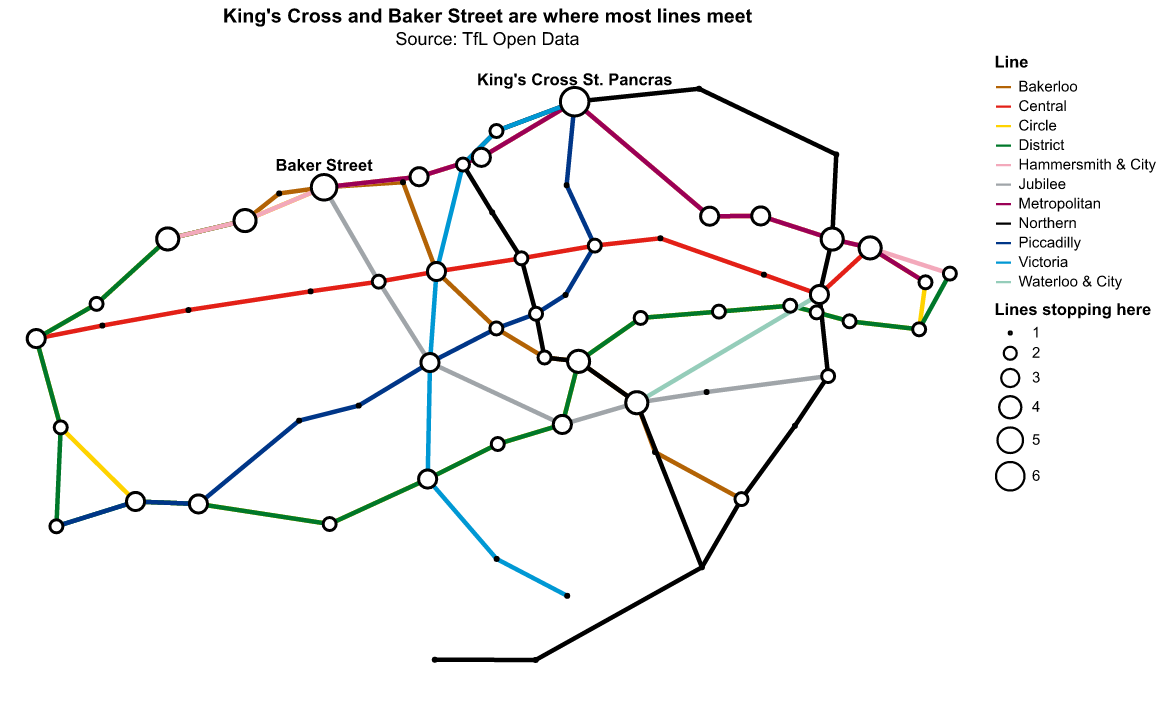

> **Teacher:** **Expected:** position is **geography** (longitude, latitude), not a computed layout; size is the **number of
> lines** (King's Cross 6, Baker Street 5). It is bad at showing how strongly lines share stations (shared track is
> drawn on top of itself, so one line hides another), and labels crowd in the centre.
> **Sample answers.** *Full marks:* "Position is where the station really is; size is how many lines stop; you
> can't see which lines run on the same track, because they're drawn on top of each other." *Low:* "It shows the
> Tube."

## D · A network of lines, as a grid (25 min · tutorial §5, §5b)

Turn the question round: now the **nodes are the 11 lines**, and two lines are linked when they **share a
station**. The more stations they share, the stronger the link: its **weight**. This is exactly tutorial §5b,
with lines instead of people and stations instead of clubs.

**D1a.** Merge `served` with itself on the column two lines have in common, and look at the first rows.

In [9]:
both = served.merge(served, on='station')
check('line_x' in both.columns and (both['station'] == "King's Cross St. Pancras").sum() == 36,
      'right: every pair of lines at each station', 'merge on the column two LINES share (tutorial §5b merged on club)')
both.head(8)

✅ right: every pair of lines at each station


,station,line_x,colour_x,line_y,colour_y
0,Elephant & Castle,Bakerloo,#B36305,Bakerloo,#B36305
1,Elephant & Castle,Bakerloo,#B36305,Northern,#000000
2,Lambeth North,Bakerloo,#B36305,Bakerloo,#B36305
3,Embankment,Bakerloo,#B36305,Bakerloo,#B36305
4,Embankment,Bakerloo,#B36305,Circle,#FFD300
5,Embankment,Bakerloo,#B36305,District,#00782A
6,Embankment,Bakerloo,#B36305,Northern,#000000
7,Charing Cross,Bakerloo,#B36305,Bakerloo,#B36305


<details><summary>💡 <b>Hint</b></summary>

In tutorial §5b, people were linked when they shared a **club**, so the merge was `on='club'`. Here lines are
linked when they share a … ? Merging on `'line'` instead pairs each station with every other station on the
same line: a different network.
</details>

> 👀 **You should see:** ✅, then rows like `Aldgate | Circle | … | Circle` and `Aldgate | Circle | … | Metropolitan`: one station with two lines that stop there, `line_x` and `line_y`.

**D1b.** Drop each line paired with itself, then count the stations each pair of lines shares.

In [10]:
both = both[both['line_x'] != both['line_y']]
shared = both.groupby(['line_x', 'line_y']).size().reset_index(name='stations')
check(shared['stations'].max() == 18, 'right: the most shared is 18 stations', "keep the rows where the two lines are NOT the same")
shared.sort_values('stations', ascending=False).head(6)

✅ right: the most shared is 18 stations


,line_x,line_y,stations
31,District,Circle,18
22,Circle,District,18
39,Hammersmith & City,Circle,10
23,Circle,Hammersmith & City,10
58,Metropolitan,Circle,9
25,Circle,Metropolitan,9


> 👀 **You should see:** ✅, then Circle–District 18 (twice, once each way round), then Circle–Hammersmith & City 10, Circle–Metropolitan 9.

**D2.** Draw it as a **grid**, as in tutorial §5: one row and one column per line, the square's shade for how
many stations they share, and the number written in it. Rows go from the line with the most stations to the
fewest.

In [11]:
order = served['line'].value_counts().index.tolist()   # most stations first, as in tutorial §5

cells = alt.Chart(shared).encode(
    x=alt.X('line_x:N', sort=order, title=None, axis=alt.Axis(labelAngle=-45)),
    y=alt.Y('line_y:N', sort=order, title=None))
squares = cells.mark_rect().encode(
    color=alt.Color('stations:Q', scale=alt.Scale(scheme='blues'), title='Stations shared'),
    tooltip=['line_x:N', 'line_y:N', 'stations:Q'])
numbers = cells.mark_text(fontSize=11).encode(
    text='stations:Q',
    color=alt.condition('datum.stations > 8', alt.value('white'), alt.value('black')))   # light text on dark squares

(squares + numbers).properties(
    width=400, height=400,
    title=alt.Title('Circle and District share the most stations', subtitle='Source: TfL Open Data')
).configure_view(stroke=None)

alt.LayerChart(...)

<details><summary>💡 <b>Hint</b></summary>

As `'scenes:Q'` in tutorial §5: the weight column's name, with `:Q` because it is a number. `'stations:N'` also
draws, but as separate colours with no order.
</details>

> 👀 **You should see:** an 11 × 11 grid of blue squares with numbers, darkest at Circle–District (18); the diagonal is empty; each number appears twice, mirrored.

> 🖼️ **Plan B: the chart, as a picture**
>
> 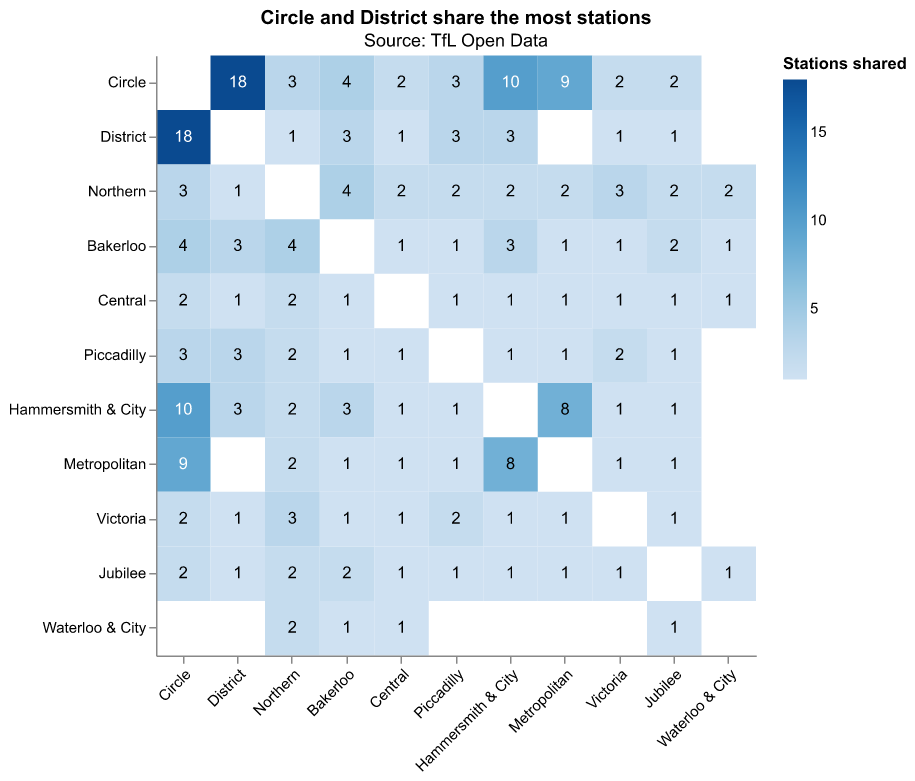

To compare, here is the same network as **dots and lines**: the 11 lines on a circle, joined when they share a
station, thicker for more. (Just run it.)

In [12]:
import math
ring = pd.DataFrame({'line': order})
ring['x'] = [math.cos(2 * math.pi * i / len(order)) for i in range(len(order))]
ring['y'] = [math.sin(2 * math.pi * i / len(order)) for i in range(len(order))]
spokes = (shared[shared['line_x'] < shared['line_y']]   # each pair once
    .merge(ring, left_on='line_x', right_on='line')
    .merge(ring, left_on='line_y', right_on='line', suffixes=('', '2')))
at = dict(x=alt.X('x:Q', axis=None, scale=alt.Scale(domain=[-1.4, 1.4])),
          y=alt.Y('y:Q', axis=None, scale=alt.Scale(domain=[-1.25, 1.25])))
alt.layer(
    alt.Chart(spokes).mark_rule(color='steelblue', opacity=0.6).encode(
        **at, x2='x2:Q', y2='y2:Q', strokeWidth=alt.StrokeWidth('stations:Q', title='Stations shared', scale=alt.Scale(range=[1, 10]))),
    alt.Chart(ring).mark_circle(size=200, color='black', opacity=1).encode(**at),
    alt.Chart(ring).mark_text(dy=-16, fontWeight='bold').encode(**at, text='line:N'),
).properties(width=460, height=420, title='The same network as dots and lines').configure_view(stroke=None)

alt.LayerChart(...)

> 👀 **You should see:** 11 line names round a circle, joined by 48 crossing blue lines of different widths.

> 🖼️ **Plan B: the chart, as a picture**
>
> 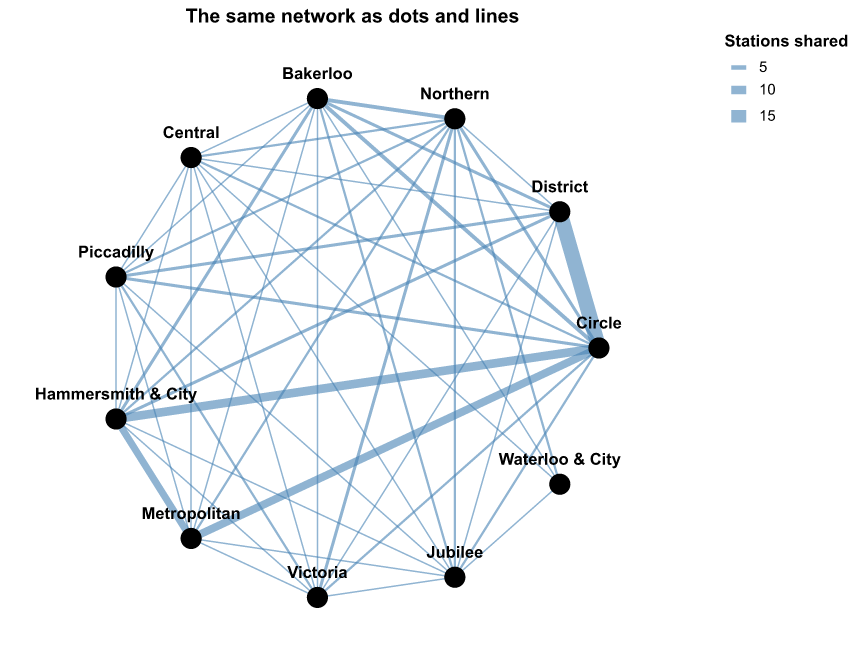

> **Teacher:** **Expected:** **Circle and District** share 18 stations; then Circle–Hammersmith & City (10), Circle–Metropolitan
> (9), Hammersmith & City–Metropolitan (8). There are 48 linked pairs among 11 lines, each with a **weight**: as dots
> and lines that is 48 crossing lines whose widths must be compared; in the grid each pair is one square with its
> number, and the Circle line's links are one row.
> **Sample answers.** *Full marks:* "Circle and District, 18. The grid: I read across the Circle row and every
> number is there, while in the circle picture the lines cross and widths are hard to compare." *Low:* "The grid
> looks neater."
> **Watch for:** D1a merged `on='line'` (pairs stations, not lines; D1b then fails with `KeyError: 'line_x'`).

## F · Choose and justify (10 min · tutorial §0, §6)

For each reader, choose **dots and lines**, **a grid**, or **boxes / bars inside each other**. Give one reason,
and say why **not** one of the other two. Use the pictures you made (the council's question is about tutorial §6).

1. A visitor at Paddington asks: *"Can I get to Bank, and where do I change?"*
2. TfL planners ask: *"Which line shares the most stations with the Circle line?"*
3. A council asks: *"Which areas of London have the most people, and which boroughs make them up?"*

> **Teacher:** **Expected:** (1) **dots and lines**: a route is a path to follow by eye, which a grid is bad at (Ghoniem et al.,
> 2004) and boxes cannot show; a schematic Tube map is also node-link, so accept it. (2) **a grid**: read the Circle
> row; District shares 18. Accept dots and lines if the student argues from line widths, but ask them to read the
> number. (3) **boxes or bars inside each other**: boroughs sit inside one area each, so it is a tree and size is the
> question; the indented list with bars (tutorial §6b) is equally good for ranking areas.
> **Sample answer (full marks):** "1: dots and lines, because she needs to follow a route; not a grid, which
> shows pairs but not paths." **Low:** "1: dots and lines." (choice, no reason.)

## E · Is the Tube a tree? (10 min · tutorial §6c and *When does a tree lie?*) · if you have time, or at home

A **tree** needs every child to have exactly **one** parent. Suppose we try Tube → line → station.

**E1.** How many stations have more than one line? (Use `lines_at` from C1. Tutorial §1: adding up `True`s counts them.)

In [13]:
print((lines_at > 1).sum(), 'of', len(lines_at), 'stations are on more than one line')
lines_at.value_counts().sort_index().rename('stations')   # how many stations have 1, 2, 3 ... lines

43 of 65 stations are on more than one line


lines
1    22
2    23
3    12
4     6
5     1
6     1
Name: stations, dtype: int64

> 👀 **You should see:** `43 of 65 stations are on more than one line`, then a small table: 22 stations with 1 line, 23 with 2, 12 with 3, 6 with 4, 1 with 5, 1 with 6.

**E2.** Pretend it is a tree anyway, and draw an icicle as in tutorial §6c: one bar per level, **counting**
stations (tutorial §5b showed how to count rows in a chart). The red line marks how many stations there really are.

In [14]:
rows = pd.concat([
    served.assign(level='1 Tube', name='Tube', colour='#888888'),
    served.assign(level='2 Line', name=served['line']),
    served.assign(level='3 Station', name=served['station']),
])
rows['path'] = rows['line'] + rows['station']   # keep stations under their line, as in tutorial §6c

bars = alt.Chart(rows).mark_bar(stroke='white').encode(
    y=alt.Y('level:O', title=None),
    x=alt.X('count():Q', title='Stations counted'),
    detail='name:N',
    order=alt.Order('min(path):N'),
    color=alt.Color('colour:N', scale=None),
    tooltip=['name:N'])
real = alt.Chart(pd.DataFrame({'n': [len(stations)]}))
truth = real.mark_rule(color='red', strokeWidth=3).encode(x='n:Q') + real.mark_text(
    color='red', align='left', dx=4, dy=-62, fontWeight='bold').encode(x='n:Q', text=alt.value('65 real stations'))

(bars + truth).properties(
    width=640, height=180,
    title=alt.Title('The Tube forced into a tree counts 139 stations', subtitle='Source: TfL Open Data'))

alt.LayerChart(...)

<details><summary>💡 <b>Hint</b></summary>

`'count():Q'` counts rows, as in tutorial §5b. `'sum(...)'` adds up a column, and `'station:Q'` treats names as
numbers: both draw an empty chart with no error.
</details>

> 👀 **You should see:** three bars, each 139 long: a grey Tube bar, the Line bar in TfL colours, the Station bar in thin slices; a red line at 65 marked '65 real stations'.

> 🖼️ **Plan B: the chart, as a picture**
>
> 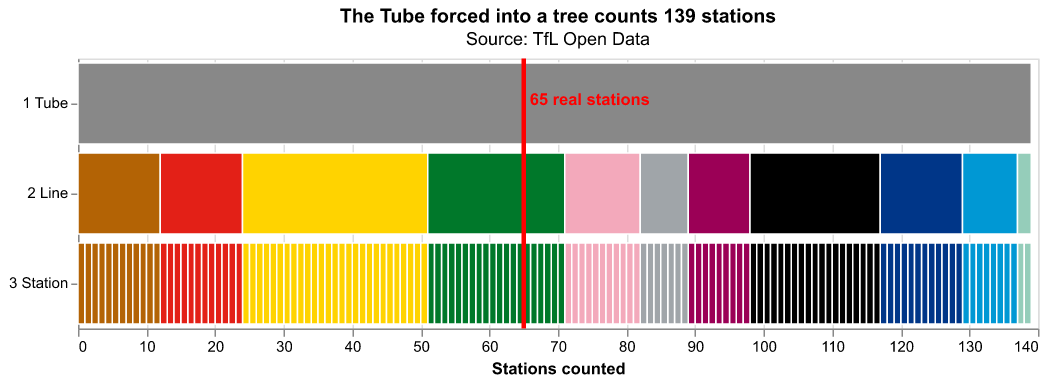

> **Teacher:** **Expected:** **43 of 65** stations are on more than one line, so a station has several "parents": it is a
> network, not a tree. The icicle draws **139** station boxes for **65** stations (King's Cross appears six times),
> so it overstates the network by more than double.
> **Sample answers.** *Full marks:* "No: 43 stations have more than one parent line, so the icicle draws them
> several times and counts 139 instead of 65." *Low:* "No, because the bars are wrong."

**Marking guide** (if the activity is assessed; 12 marks)

| | 3 (secure) | 2 | 1 | 0 |
|---|---|---|---|---|
| **Reading the data** (A, B) | Explains a row as one line's track and why degree differs by what is counted | Correct numbers, partial reason | Numbers only | Missing |
| **Building** (C, D) | Both charts run, correctly encoded, titled with a source | Both run, minor encoding slip | One chart | None |
| **Choosing** (F) | Three choices, each justified by the reader's task and a "why not" | Three choices, thin reasons | One or two | Missing |
| **Trees** (E) | Says why it is not a tree and what the icicle overstates | One of the two | Number only | Missing |

**If students finish early:** in D2, keep only one half of the grid (`shared[shared['line_x'] < shared['line_y']]`)
and discuss whether it reads better; or in C2, name Paddington and Bank too (`|| datum.name == 'Bank'`).